# Baseline：等权近期状态与历史交锋

**研究问题：** 在相同基础信息 B 上，近期五场 F 和历史交锋成绩 H，哪一块对赛果预测更有帮助？它们与赔率是什么关系？

采用简单的多分类逻辑回归建立参照。F/H/Elo 有相关性，使用相同模型、相同样本的输入组对照，而不只看单变量相关系数。

**输入：** `data/processed/candidate_features.csv`。F 和 H 读取 `selected_features.csv` 里筛选后的列。只需先运行 `preprocess.ipynb`。

**输出：** M/O/Q 的三项概率、评分、配对区间和系数保存在 `data/results/baseline/`；解释写入 `reports/reports.md`。默认复用已保存模型，`RETRAIN=True` 才强制重训；新环境缺少模型时会运行完整训练。

## 1. 读取共同特征和时间划分

B/F/H/Q 的逐列定义和公式见 preprocess。数值变量在训练期标准化，联赛按训练期独热编码。最终拟合使用截至 2022 年的训练加验证数据；测试期只生成预测。


In [1]:
from pathlib import Path
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import pearsonr, spearmanr
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits

ROOT = Path.cwd()
if not (ROOT / "data/processed/candidate_features.csv").exists():
    ROOT = ROOT.parent
RETRAIN = False
SEED, EPS = (20261028, 1e-15)
C_GRID = [0.01, 0.1, 1.0]
TRAIN_END, VALID_END, TEST_END = ("2020-12-31", "2022-12-31", "2024-12-31")
CLASSES = ["H", "D", "A"]
FIGURES = ROOT / "reports/figures"
FIGURES.mkdir(parents=True, exist_ok=True)
features = pd.read_csv(ROOT / "data/processed/candidate_features.csv", parse_dates=["MatchDate"])
features = features.sort_values(["MatchDate", "SourceRow"]).reset_index(drop=True)
B = ["elo_diff", "h2h_count", "h2h_missing"]
selected = pd.read_csv(ROOT / "data/processed/selected_features.csv")
F = selected.loc[selected.group.eq("recent_form"), "feature"].tolist()
H = selected.loc[selected.group.eq("head_to_head"), "feature"].tolist()
print("Recent form:", F)
print("Head-to-head:", H)
Q = ["q_log_H_D", "q_log_A_D"]
OUT = ROOT / "data/results/baseline"
(OUT / "models").mkdir(parents=True, exist_ok=True)
train = features.loc[features.split.eq("train")].reset_index(drop=True)
validation = features.loc[features.split.eq("validation")].reset_index(drop=True)
test = features.loc[features.split.eq("test")].reset_index(drop=True)
final_train = pd.concat([train, validation], ignore_index=True)
assert (
    train.MatchDate.max() < validation.MatchDate.min() < test.MatchDate.min()
), "Time splits overlap."
print("Train / validation / test:", len(train), len(validation), len(test))


Recent form: ['recent_ppg_diff', 'recent_gd_diff', 'recent_win_rate_diff', 'recent_goals_for_diff', 'recent_goals_against_diff']
Head-to-head: ['h2h_ppg_diff', 'h2h_gd', 'h2h_win_rate', 'h2h_goals_for', 'h2h_goals_against']
Train / validation / test: 106288 12598 11772


## 2. 模型与评价函数

**问题:** 近期、交锋、Elo 和赔率互相相关。只训练一个包含全部变量的模型，看不出多出来的预测力来自哪一块。

**解决办法:** 训练 13 个相同类型的 L2 多分类逻辑回归。每场比赛先构成一行，各模型只读取自己的列。M 系列预测赛果，O 系列拟合赔率分布，Q 系列在已知赔率后再预测赛果。Market 不训练，直接输出赔率概率。

一场比赛的输出是三项概率，顺序固定为 H、D、A：

$$
p_k=\frac{\exp(w_k^\top x)}{\sum_{j\in\{H,D,A\}}\exp(w_j^\top x)},\qquad k\in\{H,D,A\},\qquad p_H+p_D+p_A=1
$$

数值列在进入 $x$ 之前按训练集标准化，$z=(u-\mu)/\sigma$。`Division` 按训练集做独热编码；验证集或测试集中未见过的联赛编码为全 0。Qcal 不含 `Division`。每场比赛等权，不使用类别平衡权重。

| 模型 | 输入 $x$ | 训练标签 | 输出 |
|---|---|---|---|
| M0 | `Division`, B | `FTResult` | $(p_H,p_D,p_A)$ |
| M1 | `Division`, B, F | `FTResult` | $(p_H,p_D,p_A)$ |
| M2 | `Division`, B, H | `FTResult` | $(p_H,p_D,p_A)$ |
| M3 | `Division`, B, F, H | `FTResult` | $(p_H,p_D,p_A)$ |
| O0–O3 | 与 M0–M3 相同，不含赔率 | $q=(q_H,q_D,q_A)$ | $(p_H,p_D,p_A)$ |
| Market | 无 | 无 | $(q_H,q_D,q_A)$ |
| Qcal | Q | `FTResult` | $(p_H,p_D,p_A)$ |
| Q0 | `Division`, Q, B | `FTResult` | $(p_H,p_D,p_A)$ |
| Q1 | `Division`, Q, B, F | `FTResult` | $(p_H,p_D,p_A)$ |
| Q2 | `Division`, Q, B, H | `FTResult` | $(p_H,p_D,p_A)$ |
| Q3 | `Division`, Q, B, F, H | `FTResult` | $(p_H,p_D,p_A)$ |

例。一场比赛的原始值为 `Division=E0`，`B=(150, 2, 0)`，`F=(1.0, 1.2, 0.3)`，`H=(1.5, 1.0, 0.5)`，`Q=(0.405, -0.693)`，对应 $q=(0.500, 0.333, 0.167)$。M0 的输入是联赛 E0 与 `(150, 2, 0)`；M1 在其后追加 `(1.0, 1.2, 0.3)`。两个模型都输出三个概率，数值因输入不同而不同。

O 系列把每场训练比赛复制为三行，标签依次为 H、D、A，权重依次为 $q_H,q_D,q_A$。预处理器仍在未复制的训练比赛上拟合。输入中不包含赔率本身，只有拟合目标是赔率。最小化

$$
L_O=-\sum_{k\in\{H,D,A\}} q_k\log p_k
$$

M 系列与 Q 系列的单场训练损失为 $-\log p_y$，$y$ 为本场 `FTResult`。

评价时 $y$ 为真实赛果。Log Loss 与 Brier 越小越好。O 系列另以 $\mathrm{KL}(q\Vert p)$ 衡量预测分布与赔率分布的距离。

$$
\mathrm{LogLoss}=-\log p_y
$$

$$
\mathrm{Brier}=\sum_{k\in\{H,D,A\}}(p_k-\mathbf{1}_{y=k})^2
$$

$$
\mathrm{Accuracy}=\mathbf{1}\{\arg\max_k p_k=y\}
$$

$$
\mathrm{KL}(q\Vert p)=\sum_{k\in\{H,D,A\}} q_k\log\frac{q_k}{p_k}
$$

若真实赛果为主胜，预测为 $(0.50, 0.30, 0.20)$，该场 Log Loss 为 $-\log 0.50$，Brier 为 $(0.50-1)^2+(0.30-0)^2+(0.20-0)^2$。

接口依据：[scikit-learn LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)。当前 1.9 接口用 `l1_ratio=0` 指定 L2，避免已弃用的 `penalty` 参数。


In [2]:
def normalize_probabilities(p):
    p = np.asarray(p, dtype=float)
    assert p.ndim == 2 and p.shape[1] == 3 and np.isfinite(p).all()
    assert (p >= 0).all() and np.allclose(p.sum(axis=1), 1, atol=1e-08)
    p = np.clip(p, EPS, 1)
    return p / p.sum(axis=1, keepdims=True)


def match_losses(frame, probabilities):
    p = normalize_probabilities(probabilities)
    target_q = frame[["q_H", "q_D", "q_A"]].to_numpy(float)
    y = frame.y.to_numpy(int)
    one_hot = np.eye(3)[y]
    return {
        "log_loss": -np.log(p[np.arange(len(frame)), y]),
        "brier": np.square(p - one_hot).sum(axis=1),
        "accuracy": (p.argmax(axis=1) == y).astype(float),
        "kl_to_odds": np.sum(target_q * (np.log(target_q) - np.log(p)), axis=1),
        "odds_probability_mae": np.abs(target_q - p).mean(axis=1),
    }


def load_predictions(route):
    path = ROOT / "data/results" / route / "test_predictions.csv"
    if not path.exists():
        return {}
    result = {}
    for name, part in pd.read_csv(path, parse_dates=["MatchDate"]).groupby("model", sort=False):
        assert part.SourceRow.is_unique and set(part.SourceRow) == set(
            test.SourceRow
        ), "Prediction sample mismatch."
        part = part.set_index("SourceRow").loc[test.SourceRow]
        assert np.array_equal(part.y, test.y), "Prediction labels are misaligned."
        assert np.array_equal(
            part.MatchDate.to_numpy(), test.MatchDate.to_numpy()
        ), "Prediction dates are misaligned."
        assert np.array_equal(
            part.HomeTeam.to_numpy(), test.HomeTeam.to_numpy()
        ) and np.array_equal(
            part.AwayTeam.to_numpy(), test.AwayTeam.to_numpy()
        ), "Prediction teams are misaligned."
        assert np.allclose(
            part[["q_H", "q_D", "q_A"]], test[["q_H", "q_D", "q_A"]], atol=1e-12, rtol=0
        ), "Market probabilities changed."
        result[name] = normalize_probabilities(part[["p_H", "p_D", "p_A"]].to_numpy())
    return result


def save_results(predictions):
    losses = {name: match_losses(test, p) for name, p in predictions.items()}
    scores = pd.DataFrame(
        [
            {"model": name, "matches": len(test), **{k: float(v.mean()) for k, v in values.items()}}
            for name, values in losses.items()
        ]
    )
    scores.to_csv(OUT / "test_scores.csv", index=False)
    parts = []
    for name, p in predictions.items():
        part = test[
            [
                "SourceRow",
                "MatchDate",
                "Division",
                "HomeTeam",
                "AwayTeam",
                "FTResult",
                "y",
                "q_H",
                "q_D",
                "q_A",
            ]
        ].copy()
        part.insert(0, "model", name)
        part[["p_H", "p_D", "p_A"]] = p
        parts.append(part)
    pd.concat(parts, ignore_index=True).to_csv(OUT / "test_predictions.csv", index=False)
    pd.DataFrame(
        [
            {
                "year": int(year),
                "model": name,
                **{k: float(v[test.year.eq(year)].mean()) for k, v in values.items()},
            }
            for year in sorted(test.year.unique())
            for name, values in losses.items()
        ]
    ).to_csv(OUT / "test_scores_by_year.csv", index=False)
    return (scores, losses)


def fit_classifier(X, frame, target, C):
    if target == "odds":
        train_X = np.repeat(X, 3, axis=0)
        train_y = np.tile(np.arange(3), len(frame))
        weights = frame[["q_H", "q_D", "q_A"]].to_numpy(float).ravel()
    else:
        train_X, train_y, weights = (X, frame.y.to_numpy(int), None)
    for max_iter in [2000, 10000]:
        model = LogisticRegression(
            C=C, l1_ratio=0, solver="lbfgs", tol=1e-07, max_iter=max_iter, random_state=SEED
        )
        with warnings.catch_warnings(record=True) as seen, threadpool_limits(limits=1):
            warnings.simplefilter("always", ConvergenceWarning)
            model.fit(train_X, train_y, sample_weight=weights)
        convergence_warning = any((issubclass(w.category, ConvergenceWarning) for w in seen))
        if not convergence_warning and model.n_iter_.max() < max_iter:
            return model
    raise RuntimeError("Logistic regression did not converge.")


def make_preprocessor(columns, include_division=True):
    transformers = [("numeric", StandardScaler(), columns)]
    if include_division:
        transformers.append(
            ("division", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["Division"])
        )
    return ColumnTransformer(transformers, remainder="drop", sparse_threshold=0)


specs = {}
for suffix, extra in [("0", []), ("1", F), ("2", H), ("3", F + H)]:
    specs["M" + suffix] = {
        "group": "outcome",
        "target": "outcome",
        "columns": B + extra,
        "division": True,
    }
    specs["O" + suffix] = {
        "group": "odds_fit",
        "target": "odds",
        "columns": B + extra,
        "division": True,
    }
    specs["Q" + suffix] = {
        "group": "odds_increment",
        "target": "outcome",
        "columns": B + Q + extra,
        "division": True,
    }
specs["Qcal"] = {"group": "odds_calibration", "target": "outcome", "columns": Q, "division": False}
model_order = ["M0", "M1", "M2", "M3", "O0", "O1", "O2", "O3", "Qcal", "Q0", "Q1", "Q2", "Q3"]
TIE_TOLERANCE = 1e-08


## 3. 选择参数或复用模型

C 候选为 0.01、0.1、1，M/Q 按验证 Log Loss、O 按验证 KL 选择。baseline 分数相差不超过 1e-8 时取较小 C。选定后在训练加验证数据上最终拟合。O 把每场复制成三类，权重为 q，等价于软目标交叉熵；每场权重和为 1。


In [3]:
model_order = list(specs)
selected, validation_rows = ({}, [])
reuse_models = not RETRAIN and all(
    ((OUT / "models" / (name + ".joblib")).exists() for name in model_order)
)
if reuse_models:
    saved_columns = joblib.load(OUT / "models" / "M3.joblib")["spec"]["columns"]
    if saved_columns != specs["M3"]["columns"]:
        print("Saved models use different features. Retraining.")
        reuse_models = False
if reuse_models:
    print("Using saved logistic regression models; no training.")
else:
    for name, spec in specs.items():
        prep = make_preprocessor(spec["columns"], spec["division"])
        X_train, X_val = (prep.fit_transform(train), prep.transform(validation))
        candidates = []
        for C in C_GRID:
            estimator = fit_classifier(X_train, train, spec["target"], C)
            with threadpool_limits(limits=1):
                p = estimator.predict_proba(X_val)
            metric = "kl_to_odds" if spec["target"] == "odds" else "log_loss"
            score = float(match_losses(validation, p)[metric].mean())
            candidates.append((score, C))
            validation_rows.append({"model": name, "C": C, "score": score})
        best = min((x[0] for x in candidates))
        chosen = min((x[1] for x in candidates if x[0] <= best + TIE_TOLERANCE))
        selected[name] = {
            "C": chosen,
            "validation_score": min((x[0] for x in candidates if x[1] == chosen)),
        }
    pd.DataFrame(validation_rows).to_csv(OUT / "validation_scores.csv", index=False)
    (OUT / "selection.json").write_text(
        json.dumps({"selected": selected, "specs": specs, "C_grid": C_GRID}, indent=2)
    )
    for name, spec in specs.items():
        prep = make_preprocessor(spec["columns"], spec["division"])
        X = prep.fit_transform(final_train)
        model = fit_classifier(X, final_train, spec["target"], selected[name]["C"])
        joblib.dump(
            {
                "preprocessor": prep,
                "model": model,
                "spec": spec,
                "name": name,
                "C": selected[name]["C"],
                "classes": CLASSES,
                "train_end": VALID_END,
            },
            OUT / "models" / (name + ".joblib"),
        )
predictions, bundles = ({}, {})
for name in model_order:
    bundle = joblib.load(OUT / "models" / (name + ".joblib"))
    bundles[name] = bundle
    with threadpool_limits(limits=1):
        predictions[name] = normalize_probabilities(
            bundle["model"].predict_proba(bundle["preprocessor"].transform(test))
        )
predictions["Market"] = test[["q_H", "q_D", "q_A"]].to_numpy(float)
pd.DataFrame(
    [
        {
            "model": name,
            "target": spec["target"],
            "inputs": ", ".join((["Division"] if spec["division"] else []) + spec["columns"]),
        }
        for name, spec in specs.items()
    ]
).to_csv(OUT / "model_inputs.csv", index=False)
scores, loss_arrays = save_results(predictions)
display(scores.round(6))

,model,matches,log_loss,brier,accuracy,kl_to_odds,odds_probability_mae
0,M0,11772,1.003156,0.599690,0.502718,0.014592,0.040264
1,O0,11772,1.003833,0.600160,0.503398,0.013099,0.038584
2,Q0,11772,0.986386,0.588625,0.519793,0.001142,0.011570
3,M1,11772,1.002627,0.599301,0.501699,0.014083,0.039723
4,O1,11772,1.003267,0.599759,0.504247,0.012365,0.037847
5,Q1,11772,0.986350,0.588599,0.519368,0.001380,0.012802
6,M2,11772,1.003151,0.599685,0.503313,0.014497,0.040108
7,O2,11772,1.003780,0.600125,0.504247,0.013000,0.038405
8,Q2,11772,0.986444,0.588651,0.520217,0.001162,0.011658
9,M3,11772,1.002606,0.599283,0.501699,0.013961,0.039546


## 4. 评价方法：每场先算，再对比赛平均

对真实赛果 $y$，模型给出 $p=(p_H,p_D,p_A)$；归一化赔率给出 $q$。

$$\mathrm{LogLoss}=-\log p_y,\qquad \mathrm{Brier}=\sum_k(p_k-\mathbf1\{y=k\})^2.$$

$$\mathrm{KL}(q\Vert p)=\sum_k q_k\log(q_k/p_k),\qquad \mathrm{MAE}=\frac13\sum_k|q_k-p_k|.$$

Log Loss、Brier、KL、MAE 越低越好；Accuracy 越高越好。MAE 为概率的绝对误差，乘 100 才是百分点。

Pearson 衡量同一类别预测与市场概率的线性相关；Spearman 衡量排序相关，主胜、平局、客胜分别计算。高相关不等于绝对误差小。

配对比较使用同场损失差 $L_{left}-L_{right}$，负数表示左边更好。每个测试年按 28 天分块，块有放回抽样 1000 次，取 2.5%/97.5% 分位数。每次按抽中的实际比赛总数计算均值，两个模型共用抽样。区间跨 0 时不认定差异稳定。这些区间不包含模型重训和选参的不确定性，也未校正多重比较。相关系数只报告点估计。


In [4]:
rng = np.random.default_rng(SEED)
block_weights = []
blocks = []
for year in sorted(test.year.unique()):
    ids = np.flatnonzero(test.year.eq(year).to_numpy())
    day_index = (test.loc[ids, "MatchDate"] - pd.Timestamp(f"{int(year)}-01-01")).dt.days.to_numpy()
    group_id = day_index // 28
    year_blocks = [ids[group_id == group] for group in np.unique(group_id)]
    n_blocks = len(year_blocks)
    draws = rng.integers(0, n_blocks, size=(1000, n_blocks))
    counts = np.zeros((1000, n_blocks), dtype=int)
    for j in range(n_blocks):
        counts[:, j] = (draws == j).sum(axis=1)
    block_weights.append(counts)
    blocks.extend(year_blocks)
weights = np.concatenate(block_weights, axis=1)
block_sizes = np.array([len(ids) for ids in blocks])
bootstrap_denominator = weights @ block_sizes


def paired_difference(left, right, metric):
    difference = loss_arrays[left][metric] - loss_arrays[right][metric]
    sums = np.array([difference[ids].sum() for ids in blocks])
    bootstrap = weights @ sums / bootstrap_denominator
    low, high = np.quantile(bootstrap, [0.025, 0.975])
    return {
        "left": left,
        "right": right,
        "metric": metric,
        "difference": float(difference.mean()),
        "ci_low": float(low),
        "ci_high": float(high),
        "ci_includes_zero": bool(low <= 0 <= high),
    }


comparisons = [
    ("M1", "M0", "log_loss"),
    ("M2", "M0", "log_loss"),
    ("M3", "M0", "log_loss"),
    ("M1", "M2", "log_loss"),
    ("M3", "M1", "log_loss"),
    ("M3", "M2", "log_loss"),
    ("O1", "O0", "kl_to_odds"),
    ("O2", "O0", "kl_to_odds"),
    ("O3", "O0", "kl_to_odds"),
    ("O1", "O2", "kl_to_odds"),
    ("O3", "O1", "kl_to_odds"),
    ("O3", "O2", "kl_to_odds"),
    ("Qcal", "Market", "log_loss"),
    ("Q0", "Qcal", "log_loss"),
    ("Q1", "Q0", "log_loss"),
    ("Q2", "Q0", "log_loss"),
    ("Q3", "Q0", "log_loss"),
]
paired = pd.DataFrame([paired_difference(*args) for args in comparisons])
paired.to_csv(OUT / "paired_comparisons.csv", index=False)
display(paired.loc[paired.left.isin(["M1", "M2", "M3"])].round(6))


,left,right,metric,difference,ci_low,ci_high,ci_includes_zero
0,M1,M0,log_loss,-0.000529,-0.001245,0.000144,True
1,M2,M0,log_loss,-0.000005,-0.000318,0.000308,True
2,M3,M0,log_loss,-0.000551,-0.001414,0.000298,True
3,M1,M2,log_loss,-0.000524,-0.001185,0.000146,True
4,M3,M1,log_loss,-0.000021,-0.000350,0.000297,True
5,M3,M2,log_loss,-0.000546,-0.001275,0.000128,True


## 5. 与博彩市场的关系

- **M 对市场：** M 用真实赛果训练，再比较其概率与市场 $q$ 的 KL、MAE 和相关系数。
- **O 拟合市场：** 输入仍是历史信息，训练目标改成 $q$，检验历史信息能解释多少市场概率差异。
- **Q 在赔率上加历史：** 赔率对数比进入输入，目标为真实赛果，检验已知赔率后历史是否还有额外预测帮助。

M、O 的输入都没有本场赔率；O 的训练目标包含赔率。两种“接近市场”的实验应分别解释，不能据此声称知道博彩公司实际采用了哪些指标。


In [5]:
BASE_MODEL, FORM_MODEL, H2H_MODEL, BOTH_MODEL = ("M0", "M1", "M2", "M3")
market_names = [
    name for name in [BASE_MODEL, FORM_MODEL, H2H_MODEL, BOTH_MODEL] if name in predictions
]
market_scores = (
    scores.set_index("model")
    .loc[market_names, ["matches", "kl_to_odds", "odds_probability_mae"]]
    .reset_index()
)
market_scores.to_csv(OUT / "m_vs_market_scores.csv", index=False)
correlation_rows = []
q = test[["q_H", "q_D", "q_A"]].to_numpy()
for name in market_names:
    for j, label in enumerate(CLASSES):
        p = predictions[name][:, j]
        correlation_rows.append(
            {
                "model": name,
                "class": label,
                "pearson": float(pearsonr(p, q[:, j]).statistic),
                "spearman": float(spearmanr(p, q[:, j]).statistic),
            }
        )
market_correlations = pd.DataFrame(correlation_rows)
market_correlations.to_csv(OUT / "m_vs_market_correlations.csv", index=False)
market_pairs = [
    (FORM_MODEL, H2H_MODEL),
    (FORM_MODEL, BASE_MODEL),
    (H2H_MODEL, BASE_MODEL),
    (BOTH_MODEL, FORM_MODEL),
    (BOTH_MODEL, H2H_MODEL),
]
market_comparisons = pd.DataFrame(
    [
        paired_difference(a, b, "kl_to_odds")
        for a, b in market_pairs
        if a in predictions and b in predictions
    ]
)
market_comparisons.to_csv(OUT / "m_vs_market_comparisons.csv", index=False)
feature_correlations = pd.DataFrame(
    [
        {
            "feature": col,
            "odds_target": "q_D" if "draw" in col else "q_H-q_A",
            "spearman": float(
                spearmanr(test[col], test.q_D if "draw" in col else test.q_H - test.q_A).statistic
            ),
        }
        for col in F + H
    ]
)
feature_correlations.to_csv(OUT / "odds_correlations.csv", index=False)
display(market_scores.round(6))
display(market_comparisons[["left", "right", "difference", "ci_low", "ci_high"]].round(6))


,model,matches,kl_to_odds,odds_probability_mae
0,M0,11772,0.014592,0.040264
1,M1,11772,0.014083,0.039723
2,M2,11772,0.014497,0.040108
3,M3,11772,0.013961,0.039546


,left,right,difference,ci_low,ci_high
0,M1,M2,-0.000414,-0.000518,-0.000316
1,M1,M0,-0.000509,-0.000623,-0.000403
2,M2,M0,-0.000095,-0.000153,-0.000036
3,M3,M1,-0.000122,-0.000178,-0.000063
4,M3,M2,-0.000536,-0.000651,-0.000431


## 6. 模型解释：系数不等于重要性百分比

数值特征已经标准化，每个输入对应 H/D/A 三个系数。因为

$$\log(p_H/p_A)=z_H-z_A,$$

其他输入不变时，一个特征增加一个训练期标准差，主胜/客胜概率比乘以 $\exp(\beta_H-\beta_A)$；这不是主胜概率增加同样百分比，也不是因果关系。近期积分差与净胜球差相关，不能只凭某个负系数删除特征。

这里保存数值系数、联赛系数、截距和训练期特征相关矩阵。不同模型系数不能直接换算成“近期占多少、交锋占多少”。


In [6]:
FOCUS_MODEL = "M3"
coefficient_rows, division_rows, intercept_rows = ([], [], [])
for name, bundle in bundles.items():
    prep, model = (bundle["preprocessor"], bundle["model"])
    scaler = prep.named_transformers_["numeric"]
    columns = bundle["spec"]["columns"]
    for j, feature in enumerate(columns):
        bh, bd, ba = model.coef_[:, j]
        contrasts = np.array([bh - bd, bh - ba, bd - ba])
        coefficient_rows.append(
            {
                "model": name,
                "feature": feature,
                "beta_H": bh,
                "beta_D": bd,
                "beta_A": ba,
                "training_sd": scaler.scale_[j],
                "training_mean": scaler.mean_[j],
                "H_minus_D": bh - bd,
                "H_minus_A": bh - ba,
                "D_minus_A": bd - ba,
                "contrast_rms": np.sqrt(np.mean(contrasts**2)),
                "ratio_H_A_per_SD": np.exp(bh - ba),
                "raw_H_minus_A_per_unit": (bh - ba) / scaler.scale_[j],
            }
        )
    for label, intercept in zip(CLASSES, model.intercept_):
        intercept_rows.append({"model": name, "class": label, "intercept": intercept})
    if "division" in prep.named_transformers_:
        categories = prep.named_transformers_["division"].categories_[0]
        for j, division in enumerate(categories):
            bh, bd, ba = model.coef_[:, len(columns) + j]
            division_rows.append(
                {"model": name, "division": division, "beta_H": bh, "beta_D": bd, "beta_A": ba}
            )
coefficients = pd.DataFrame(coefficient_rows)
coefficients.to_csv(OUT / "coefficients.csv", index=False)
pd.DataFrame(division_rows).to_csv(OUT / "division_coefficients.csv", index=False)
pd.DataFrame(intercept_rows).to_csv(OUT / "intercepts.csv", index=False)
final_train[B + F + H + Q].corr().to_csv(OUT / "training_correlations.csv")
display(
    coefficients.loc[
        coefficients.model.eq(FOCUS_MODEL),
        ["feature", "beta_H", "beta_D", "beta_A", "ratio_H_A_per_SD"],
    ].round(4)
)


,feature,beta_H,beta_D,beta_A,ratio_H_A_per_SD
63,elo_diff,0.4023,-0.0056,-0.3967,2.2233
64,h2h_count,-0.0172,-0.0105,0.0277,0.9560
65,h2h_missing,0.0118,-0.0074,-0.0044,1.0163
66,recent_ppg_diff,-0.0622,0.0020,0.0602,0.8848
67,recent_gd_diff,0.0441,-0.0060,-0.0380,1.0856
68,recent_win_rate_diff,0.0128,0.0047,-0.0175,1.0308
69,recent_goals_for_diff,0.0319,-0.0046,-0.0272,1.0609
70,recent_goals_against_diff,-0.0358,0.0046,0.0311,0.9353
71,h2h_ppg_diff,-0.0187,0.0225,-0.0038,0.9853
72,h2h_gd,0.0234,-0.0124,-0.0111,1.0351


## 7. 更新总报告

保存一张英文图，报告使用实际评分和区间。Log Loss/Brier 越低越好，准确率越高越好。


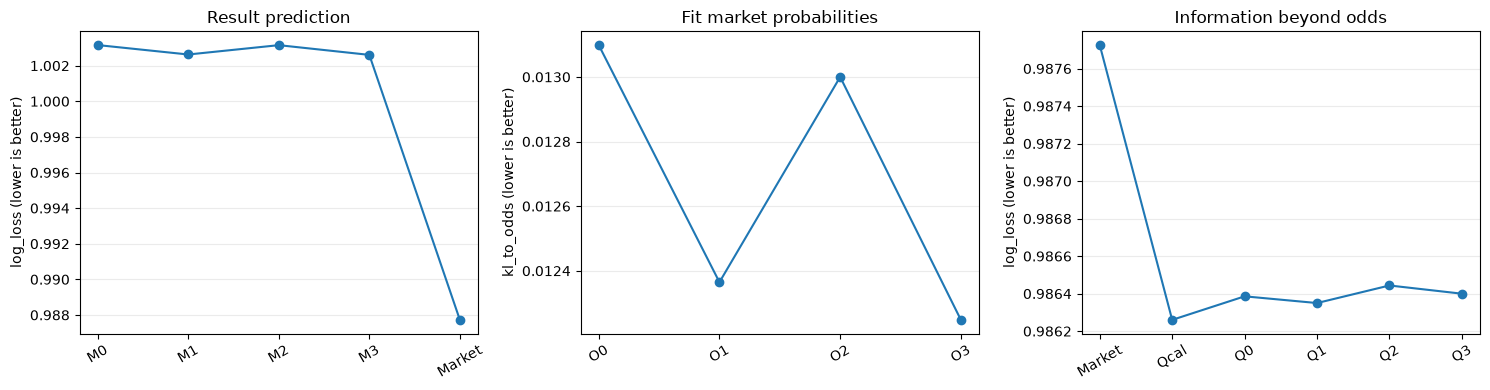

Updated reports/reports.md: baseline


In [7]:
def md_table(frame):
    rows = [
        "| " + " | ".join(map(str, frame.columns)) + " |",
        "| " + " | ".join(["---"] * len(frame.columns)) + " |",
    ]
    for values in frame.itertuples(index=False, name=None):
        rows.append(
            "| "
            + " | ".join(
                (f"{v:.6f}" if isinstance(v, (float, np.floating)) else str(v) for v in values)
            )
            + " |"
        )
    return "\n".join(rows)


def update_report(section, text):
    path = ROOT / "reports/reports.md"
    path.parent.mkdir(exist_ok=True)
    body = path.read_text(encoding="utf-8") if path.exists() else "# 足球比赛分析\n\n"
    start, end = (f"<!-- {section}:start -->", f"<!-- {section}:end -->")
    block = start + "\n" + text.strip() + "\n" + end
    if start in body:
        before, remainder = body.split(start, 1)
        _, after = remainder.split(end, 1)
        body = before + block + after
    else:
        body = body.rstrip() + "\n\n" + block + "\n"
    path.write_text(body, encoding="utf-8")
    print("Updated reports/reports.md:", section)


indexed = scores.set_index("model")
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, names, metric, title in [
    (axes[0], ["M0", "M1", "M2", "M3", "Market"], "log_loss", "Result prediction"),
    (axes[1], ["O0", "O1", "O2", "O3"], "kl_to_odds", "Fit market probabilities"),
    (axes[2], ["Market", "Qcal", "Q0", "Q1", "Q2", "Q3"], "log_loss", "Information beyond odds"),
]:
    ax.plot(names, indexed.loc[names, metric], "o-")
    ax.set(title=title, ylabel=metric + " (lower is better)")
    ax.tick_params(axis="x", rotation=30)
    ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(FIGURES / "baseline.png", dpi=160)
plt.show()
pair_cols = ["left", "right", "difference", "ci_low", "ci_high"]


def pair_table(frame):
    return md_table(frame[pair_cols])


text = "### 逻辑回归\n\n"
text += (
    f"测试集 {int(indexed.loc['M0', 'matches'])} 场。"
    "M0 = B，M1 = B + 近期，M2 = B + 交锋，M3 = B + 两者。"
    "交锋次数已经在 B 里，下面比较的是交锋成绩。\n\n"
)
text += (
    md_table(
        indexed.loc[["M0", "M1", "M2", "M3", "Market"], ["log_loss", "accuracy"]].reset_index()
    )
    + "\n\n"
)
text += "Log Loss 之差是左边减去右边。负数表示左边更低。区间是 95% 分块自助区间。\n\n"
text += (
    pair_table(
        paired.loc[
            (paired.left.eq("M1") & paired.right.isin(["M0", "M2"]))
            | (paired.left.eq("M2") & paired.right.eq("M0"))
            | (paired.left.eq("M3") & paired.right.eq("M1"))
        ]
    )
    + "\n\n"
)
m1_m2 = paired.loc[paired.left.eq("M1") & paired.right.eq("M2") & paired.metric.eq("log_loss")].iloc[0]
if bool(m1_m2.ci_includes_zero):
    result_text = "M1 减 M2 的区间包含 0。逻辑回归没有显示筛选后的近期状态和历史交锋之间有稳定差距。"
elif m1_m2.difference < 0:
    result_text = "M1 的 Log Loss 低于 M2，且区间不包含 0。在这次逻辑回归里，筛选后的近期状态比历史交锋更有帮助。"
else:
    result_text = "M2 的 Log Loss 低于 M1，且区间不包含 0。在这次逻辑回归里，筛选后的历史交锋比近期状态更有帮助。"
text += result_text + "\n\n"
market_gap = market_comparisons.loc[market_comparisons.left.eq("M1") & market_comparisons.right.eq("M2")].iloc[0]
gap = f"差为 {market_gap.difference:.6f}，区间 [{market_gap.ci_low:.6f}, {market_gap.ci_high:.6f}]"
if bool(market_gap.ci_includes_zero):
    market_text = f"相对市场概率的 KL，M1 减 M2 的{gap}，包含 0。近期状态并没有稳定地比历史交锋更接近赔率概率。"
elif market_gap.difference < 0:
    market_text = f"相对市场概率的 KL 只比较 M1 和 M2：{gap}，不包含 0。M1 更接近市场。更接近市场本身并不表示对真实赛果有更稳定的改进。"
else:
    market_text = f"相对市场概率的 KL 只比较 M1 和 M2：{gap}，不包含 0。M2 更接近市场。更接近市场本身并不表示对真实赛果有更稳定的改进。"
text += market_text + "\n\n"
o1_o2 = paired.loc[paired.left.eq("O1") & paired.right.eq("O2")].iloc[0]
if bool(o1_o2.ci_includes_zero):
    odds_fit_text = (
        f"拟合市场后，O1 减 O2 相对赔率的 KL 差为 {o1_o2.difference:.6f}，"
        f"区间 [{o1_o2.ci_low:.6f}, {o1_o2.ci_high:.6f}]，包含 0。"
    )
elif o1_o2.difference < 0:
    odds_fit_text = (
        f"拟合市场后，O1 相对赔率的 KL 比 O2 低 {-o1_o2.difference:.6f}，"
        f"区间 [{o1_o2.ci_low:.6f}, {o1_o2.ci_high:.6f}]，不包含 0。"
    )
else:
    odds_fit_text = (
        f"拟合市场后，O2 相对赔率的 KL 比 O1 低 {o1_o2.difference:.6f}，"
        f"区间 [{o1_o2.ci_low:.6f}, {o1_o2.ci_high:.6f}]，不包含 0。"
    )
text += odds_fit_text + " "
q_loss = indexed.loc[["Q0", "Q1", "Q2", "Q3"], "log_loss"]
text += (
    f"Qcal 只用赔率对数比，Log Loss 是 {indexed.loc['Qcal', 'log_loss']:.6f}。"
    "Q0 加上 B，Q1、Q2、Q3 再分别加上近期、交锋和两者；"
    f"这四者的 Log Loss 在 {q_loss.min():.6f} 到 {q_loss.max():.6f} 之间。\n\n"
)
text += (
    pair_table(paired.loc[paired.left.isin(["Q1", "Q2", "Q3"]) & paired.right.eq("Q0")])
    + "\n\n"
)
q_rows = paired.loc[paired.left.isin(["Q1", "Q2", "Q3"]) & paired.right.eq("Q0") & paired.metric.eq("log_loss")]
if bool(q_rows.ci_includes_zero.all()):
    q_text = "赔率已经进入模型后，再加入近期或交锋，没有显示赛果 Log Loss 的稳定额外下降。"
else:
    q_text = "赔率已经进入模型后，至少有一项加入历史的比较，其 95% 区间不包含 0。看表中的符号：负的差值表示更大的模型 Log Loss 更低。"
text += q_text + "\n\n"
ratios = coefficients.loc[coefficients.model.eq("M3")].set_index("feature").ratio_H_A_per_SD
rest = ratios.drop(index="elo_diff")
text += (
    "M3 的数值输入已标准化。"
    f"Elo 差增加一个标准差时，主胜相对客胜的概率比变为原来的 {float(ratios.loc['elo_diff']):.3f} 倍。"
    f"其余数值列的倍数在 {float(rest.min()):.3f} 到 {float(rest.max()):.3f} 之间。"
    "相关列会分担系数。\n\n"
)
text += "![Baseline 比较](figures/baseline.png)"
update_report("baseline", text)
